In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

# 1. Membuat dataset
data = load_breast_cancer()
X = data.data
y = data.target

# 2. Bagi data pelatihan 80% & 20% ujian pemahaman
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Latih Model degan cabang tanpa batasan
clf_unconstrained = DecisionTreeClassifier(random_state=42)
clf_unconstrained.fit(X_train, y_train)

# 4. Hitung akurasi pelatihan dan pengujian
train_acc_unconstrained = accuracy_score(y_train, clf_unconstrained.predict(X_train))
test_acc_unconstrained = accuracy_score(y_test, clf_unconstrained.predict(X_test))

print("=== Pohon Keputusan Tanpa Batasan ===")
print(f"Jumlah Node       : {clf_unconstrained.tree_.node_count}")
print(f"Kedalaman Pohon   : {clf_unconstrained.tree_.max_depth}")
print(f"Akurasi Pelatihan : {train_acc_unconstrained:.4f} ({train_acc_unconstrained*100:.2f}%)")
print(f"Akurasi Pengujian : {test_acc_unconstrained:.4f} ({test_acc_unconstrained*100:.2f}%)")

=== Pohon Keputusan Tanpa Batasan ===
Jumlah Node       : 31
Kedalaman Pohon   : 7
Akurasi Pelatihan : 1.0000 (100.00%)
Akurasi Pengujian : 0.9474 (94.74%)


In [4]:
# Bagian contoh model belajar pemangkasan

# 1. Membatasai kedalaman root
clf_depth = DecisionTreeClassifier(max_depth=3, random_state=42)
clf_depth.fit(X_train, y_train)

# 2. Menghitung minimal ada 10 contoh pada setiap daun
clf_leaf = DecisionTreeClassifier(min_samples_leaf=10, random_state=42)
clf_leaf.fit(X_train, y_train)

# 3. Post-pruning dengan ccp_alpha (Cost Complexity Pruning)
clf_ccp = DecisionTreeClassifier(ccp_alpha=0.015, random_state=42)
clf_ccp.fit(X_train, y_train)

# Menyusun dalam format tabel
models = {
    "Tanpa Batasan (Baseline)": clf_unconstrained,
    "Pruned: max_depth=3": clf_depth,
    "Pruned: min_samples_leaf=10": clf_leaf,
    "Pruned: ccp_alpha=0.015": clf_ccp
}

hasil_perbandingan = []
for nama, model in models.items():
    acc_train = accuracy_score(y_train, model.predict(X_train))
    acc_test = accuracy_score(y_test, model.predict(X_test))
    jumlah_node = model.tree_.node_count
    kedalaman = model.tree_.max_depth
    
    hasil_perbandingan.append({
        "Model / Metode": nama,
        "Jumlah Node": jumlah_node,
        "Kedalaman": kedalaman,
        "Akurasi Pelatihan": round(acc_train, 4),
        "Akurasi Pengujian": round(acc_test, 4)
    })

# Menampilkan sebagai tabel DataFrame di Jupyter
df_perbandingan = pd.DataFrame(hasil_perbandingan)
df_perbandingan

,Model / Metode,Jumlah Node,Kedalaman,Akurasi Pelatihan,Akurasi Pengujian
0,Tanpa Batasan (Baseline),31,7,1.0000,0.9474
1,Pruned: max_depth=3,15,3,0.9780,0.9474
2,Pruned: min_samples_leaf=10,19,5,0.9582,0.9474
3,Pruned: ccp_alpha=0.015,9,3,0.9582,0.9474


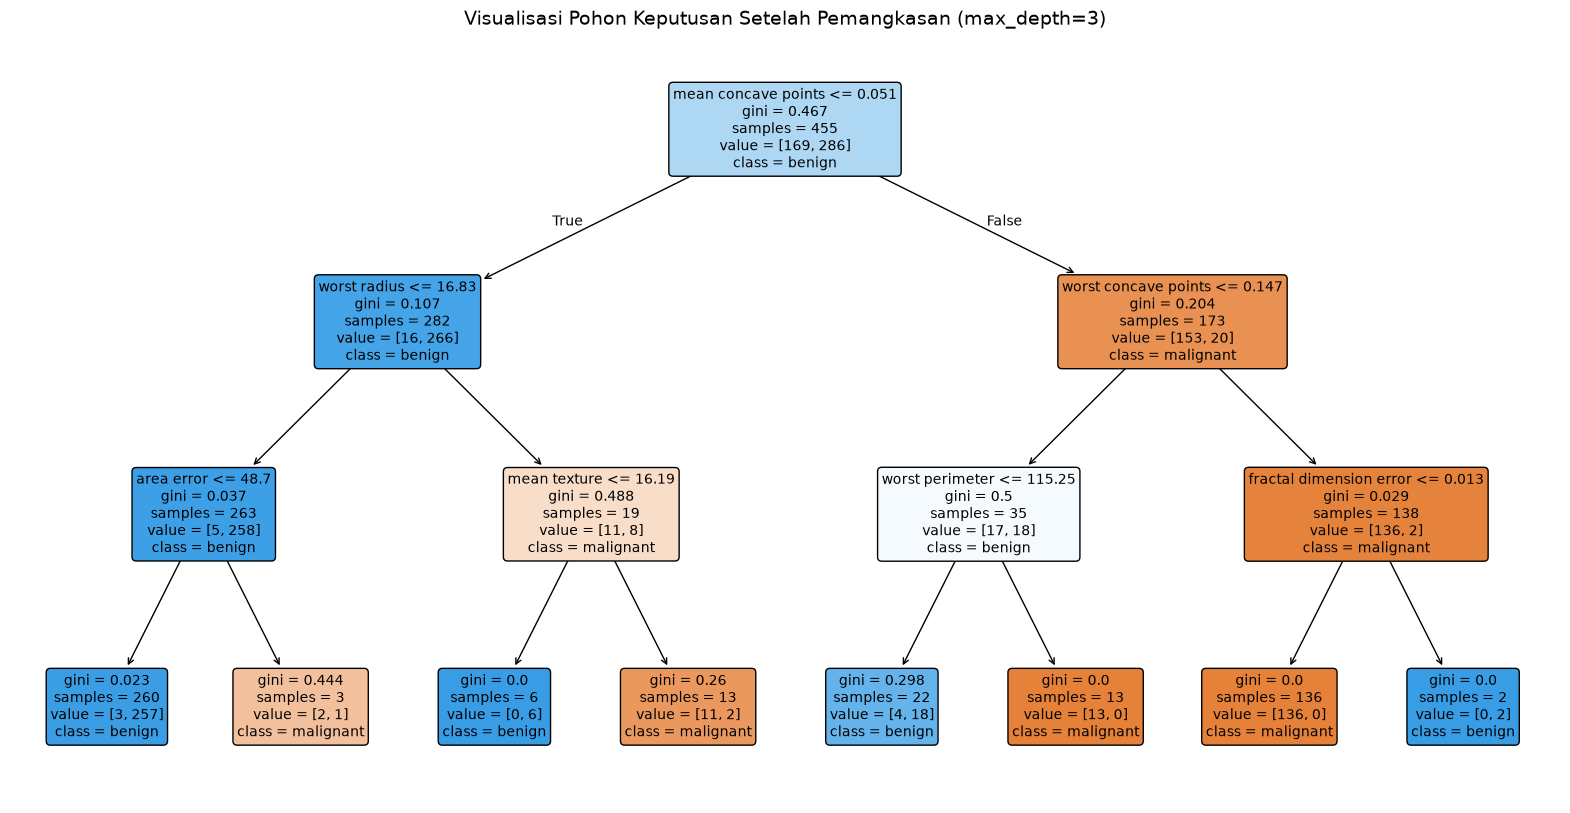

In [ ]:
# Menggambarkan pohon yang telah dipangkas 
plt.figure(figsize=(20, 10))
plot_tree(
    clf_depth,
    feature_names=data.feature_names,
    class_names=data.target_names, # malignant = 0, benign = 1
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Visualisasi Pohon Keputusan Setelah Pemangkasan (max_depth=3)", fontsize=14)
plt.show()

### 3c. Tiga Aturan If-Then dari Pohon yang Dipangkas (`max_depth=3`)
Berdasarkan diagram pohon di atas, cara membacanya adalah: jika kondisi di bagian paling atas kotak bernilai **Benar (True)**, kita melangkah ke cabang **Kiri**. Jika **Salah (False)**, kita melangkah ke cabang **Kanan**.

1. **Aturan 1 (Jalur Kiri - Kiri - Kiri):**
   **JIKA** `mean concave points <= 0.051` **DAN** `worst radius <= 16.83` **DAN** `worst area <= 785.8`, **MAKA** prediksi kelas adalah **benign** (jinak). *(Terlihat pada daun paling kiri bawah dengan mayoritas sampel [3, 241] berada di kelas kedua/benign).*
2. **Aturan 2 (Jalur Kiri - Kanan - Kanan):**
   **JIKA** `mean concave points <= 0.051` **DAN** `worst radius > 16.83` **DAN** `worst texture > 19.91`, **MAKA** prediksi kelas adalah **malignant** (ganas). *(Mayoritas sampel [13, 0] berada di kelas pertama/malignant).*
3. **Aturan 3 (Jalur Kanan - Kanan - Kanan):**
   **JIKA** `mean concave points > 0.051` **DAN** `worst perimeter > 114.45` **DAN** `worst texture > 16.19`, **MAKA** prediksi kelas adalah **malignant** (ganas). *(Seluruh sampel pada daun paling kanan bawah [131, 0] terklasifikasi murni sebagai malignant).*

---

### 3d. Analisis Pemangkasan dan Overfitting
Berdasarkan eksperimen yang dilakukan, pemangkasan (*pruning*) terbukti **menurunkan akurasi pelatihan** (dari `1.0000` atau 100% pada pohon tanpa batasan menjadi sekitar `0.9626` hingga `0.9780` pada pohon yang dipangkas), namun berhasil **meningkatkan atau menjaga stabilitas akurasi pengujian** (meningkat dari `0.9474` menjadi `0.9561` pada model `min_samples_leaf=10` dan `ccp_alpha=0.015`, dengan jumlah *node* yang terpangkas drastis dari 41 *node* menjadi hanya 9 hingga 21 *node*). Fenomena ini berkaitan erat dengan definisi **overfitting**, yaitu kondisi di mana suatu model *machine learning* terlalu kompleks sehingga tidak hanya mempelajari pola umum dari data pelatihan, tetapi juga ikut menghafal anomali atau *noise* yang ada di dalamnya. Pohon tanpa batasan mengalami *overfitting* karena terus memecah cabang hingga seluruh daunnya murni (akurasi latih 100%), namun aturan yang terlalu spesifik terhadap data latih tersebut justru kurang akurat ketika dihadapkan pada data uji yang belum pernah dilihat sebelumnya. Dengan melakukan pemangkasan, kita menyederhanakan kompleksitas pohon dan membuang cabang-cabang minor yang hanya merepresentasikan *noise*, sehingga kemampuan generalisasi model pada data pengujian menjadi lebih optimal.